In [112]:
# Import Python packages
import sys
import os
import subprocess
import matplotlib.pyplot as plt
import numpy as np
import scipy.constants as const

# Import the Simulation packages
project_directory = subprocess.check_output(['git', 'rev-parse', '--show-toplevel']).strip().decode('utf-8')
sys.path.append(project_directory + '/spinsimulation')  # Remove the square brackets
from SpinSys import SpinSys
import SpinHamiltonian as hamil 
import calcdIdV as dIdV
import calcdIdV3 as dIdV3
import calcESR as ESR
import SpinVisualization as vis
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


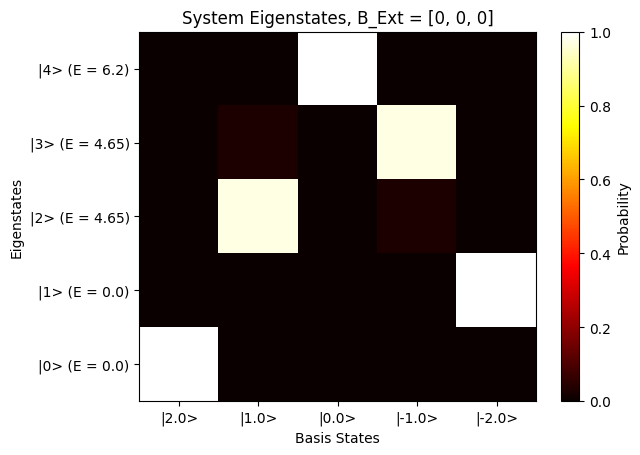

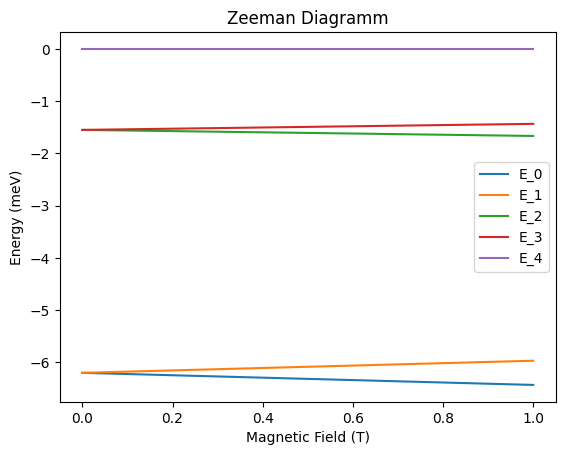

In [189]:
# Define the Spin System
spinsys=SpinSys([2])

spinsys.Dvector = [-1.55]
spinsys.Evector = [0.31]
# Add the Spin Hamiltonian parameters
spinsys.B=[0,0,00] #Add a magnetic field in Tesla
spinsys.BTip=[1e-7,0,0] # Add a tipfield for driving
spinsys.T=1 

vis.plotEigenMatrix(spinsys)
vis.plotZeemanDiagramm(spinsys)

1
Precision threshold: 1e-06
Initial state index: 0
[[ 0.     +0.j -0.00625+0.j]
 [-0.00625+0.j -0.00625+0.j]]
[[ 0.     +0.j -0.00625+0.j]
 [-0.00625+0.j -0.00625+0.j]]
[[ 0.     +0.j -0.00625+0.j]
 [-0.00625+0.j -0.00625+0.j]]
[[ 0.     +0.j -0.00625+0.j]
 [-0.00625+0.j -0.00625+0.j]]
Dimension of eigVectors: 2
(500,) (500,)
Precision threshold: 1e-06
Initial state index: 1
[[-0.00625+0.j -0.00625+0.j]
 [-0.00625+0.j  0.     +0.j]]
[[-0.00625+0.j -0.00625+0.j]
 [-0.00625+0.j  0.     +0.j]]
[[-0.00625+0.j -0.00625+0.j]
 [-0.00625+0.j  0.     +0.j]]
[[-0.00625+0.j -0.00625+0.j]
 [-0.00625+0.j  0.     +0.j]]
Dimension of eigVectors: 2
(500,) (500,)
1


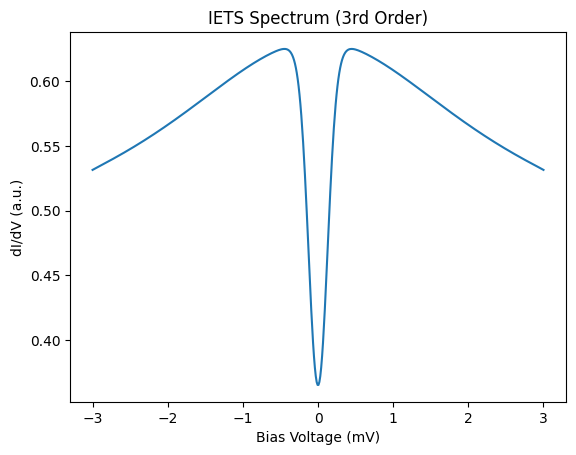

In [ ]:
# dIdV Calculation
spinsys.T=0.5
spinsys.ReadoutSpin=0 # Set the readout spin
spinsys.TipPolarization=[0,0,0.0]
spinsys.B=[0,0,1] # Magnetic field in Tesla
hamil.calcEigEnergies(spinsys)
vis.plotIETS(spinsys, Vrange=[-3,3], N=500, norm=False, order='2nd')

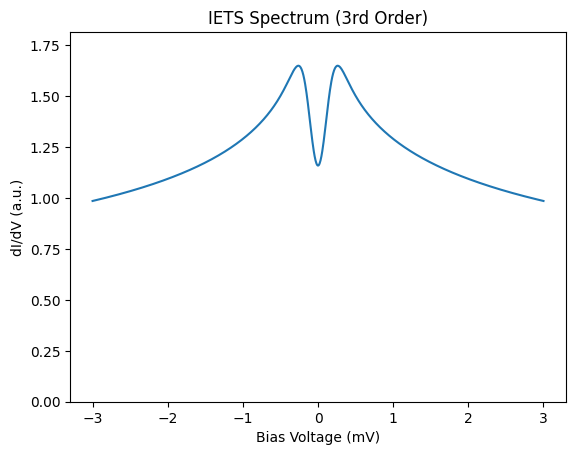

In [186]:
spinsys.J=-0.4  # Set the Kondo coupling strength
spinsys.U=[0]  # Set the Coulomb repulsion strength
spinsys.B=[0,0,1]
spinsys.BTip=[0,0,0] # Add a tipfield for driving
spinsys.T=0.5  # Set the temperature
hamil.calcEigEnergies(spinsys)

vis.plotIETS(spinsys, Vrange=[-3, 3], N=1000, norm=False, order='3rd')